In [1]:
import json
import logging
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [2]:
PROJECT_ROOT = Path.cwd().parent

DATA_PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
MODELS_DIR = PROJECT_ROOT / "models" / "supervised" / "baseline_logistic_regression"

RANDOM_SEED = 42
DEFAULT_THRESHOLD = 0.5

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
)

logger = logging.getLogger(__name__)

logger.info("Project root: %s", PROJECT_ROOT)
logger.info("Processed data directory: %s", DATA_PROCESSED_DIR)

2026-11-01 09:46:24,736 | INFO | Project root: c:\Users\use\Desktop\Credit Card Fraud Detection
2026-11-01 09:46:24,737 | INFO | Processed data directory: c:\Users\use\Desktop\Credit Card Fraud Detection\data\processed


In [3]:
def load_split(
    feature_path: Path,
    target_path: Path,
) -> tuple[pd.DataFrame, pd.Series]:
    """Load a feature matrix and target vector from Parquet files."""
    if not feature_path.exists():
        raise FileNotFoundError(f"Feature file not found: {feature_path}")

    if not target_path.exists():
        raise FileNotFoundError(f"Target file not found: {target_path}")

    features = pd.read_parquet(feature_path)
    target_dataframe = pd.read_parquet(target_path)

    if features.empty or target_dataframe.empty:
        raise ValueError("Loaded split is empty.")

    target_column = target_dataframe.columns[0]
    target = target_dataframe[target_column]

    if len(features) != len(target):
        raise ValueError("Feature and target row counts do not match.")

    return features, target


X_train, y_train = load_split(
    feature_path=DATA_PROCESSED_DIR / "train" / "X_train.parquet",
    target_path=DATA_PROCESSED_DIR / "train" / "y_train.parquet",
)

X_validation, y_validation = load_split(
    feature_path=DATA_PROCESSED_DIR / "validation" / "X_validation.parquet",
    target_path=DATA_PROCESSED_DIR / "validation" / "y_validation.parquet",
)

logger.info("Training features: %s", X_train.shape)
logger.info("Validation features: %s", X_validation.shape)
logger.info("Training class counts: %s", y_train.value_counts().sort_index().to_dict())
logger.info(
    "Validation class counts: %s",
    y_validation.value_counts().sort_index().to_dict(),
)

2026-11-01 09:46:29,735 | INFO | Training features: (198608, 30)
2026-11-01 09:46:29,737 | INFO | Validation features: (42559, 30)
2026-11-01 09:46:29,741 | INFO | Training class counts: {0: 198277, 1: 331}
2026-11-01 09:46:29,745 | INFO | Validation class counts: {0: 42488, 1: 71}


In [4]:
EXPECTED_BASE_FEATURES = ["Time", *[f"V{i}" for i in range(1, 29)], "Amount"]


def validate_model_inputs(
    features: pd.DataFrame,
    target: pd.Series,
    expected_features: list[str],
) -> None:
    """Validate feature schema, target labels, and absence of target leakage."""
    missing_features = set(expected_features) - set(features.columns)
    unexpected_features = set(features.columns) - set(expected_features)

    if missing_features:
        raise ValueError(f"Missing expected features: {sorted(missing_features)}")

    if unexpected_features:
        raise ValueError(f"Unexpected features found: {sorted(unexpected_features)}")

    if "Class" in features.columns:
        raise ValueError("Target leakage detected: 'Class' is present in features.")

    invalid_target_values = set(target.unique()) - {0, 1}
    if invalid_target_values:
        raise ValueError(
            f"Target contains invalid values: {sorted(invalid_target_values)}"
        )

    if features.isnull().any().any():
        raise ValueError("Features contain missing values.")

    if np.isinf(features.select_dtypes(include=np.number)).any().any():
        raise ValueError("Features contain non-finite values.")


validate_model_inputs(
    features=X_train,
    target=y_train,
    expected_features=EXPECTED_BASE_FEATURES,
)

validate_model_inputs(
    features=X_validation,
    target=y_validation,
    expected_features=EXPECTED_BASE_FEATURES,
)

logger.info("Training and validation inputs validated successfully.")

2026-11-01 09:46:50,260 | INFO | Training and validation inputs validated successfully.


In [5]:
def add_log_amount_feature(
    features: pd.DataFrame,
) -> pd.DataFrame:
    """Add a zero-safe logarithmic transformation of Amount."""
    if "Amount" not in features.columns:
        raise ValueError("Required column 'Amount' is missing.")

    if (features["Amount"] < 0).any():
        raise ValueError("Negative Amount values found; log1p is not appropriate.")

    transformed = features.copy()
    transformed["Amount_log1p"] = np.log1p(transformed["Amount"])
    return transformed


def add_elapsed_time_hours_feature(
    features: pd.DataFrame,
) -> pd.DataFrame:
    """Add elapsed transaction time expressed in hours."""
    if "Time" not in features.columns:
        raise ValueError("Required column 'Time' is missing.")

    transformed = features.copy()
    transformed["Time_hours"] = transformed["Time"] / 3600.0
    return transformed


def build_feature_configuration(
    features: pd.DataFrame,
    configuration_name: str,
) -> tuple[pd.DataFrame, list[str]]:
    """Create one of the defined feature-engineering configurations."""
    if configuration_name == "original_features":
        transformed = features.copy()
        selected_features = list(transformed.columns)

    elif configuration_name == "original_plus_log_amount":
        transformed = add_log_amount_feature(features)
        selected_features = list(transformed.columns)

    elif configuration_name == "log_amount_and_time_hours":
        transformed = add_log_amount_feature(features)
        transformed = add_elapsed_time_hours_feature(transformed)
        selected_features = list(transformed.columns)

    else:
        raise ValueError(f"Unknown feature configuration: {configuration_name}")

    if "Class" in transformed.columns:
        raise ValueError("Target leakage detected in engineered features.")

    return transformed[selected_features], selected_features


FEATURE_CONFIGURATIONS = [
    "original_features",
    "original_plus_log_amount",
    "log_amount_and_time_hours",
]

logger.info("Defined feature configurations: %s", FEATURE_CONFIGURATIONS)

2026-11-01 09:46:54,130 | INFO | Defined feature configurations: ['original_features', 'original_plus_log_amount', 'log_amount_and_time_hours']


In [6]:
def summarize_engineered_features(
    features: pd.DataFrame,
    target: pd.Series,
) -> pd.DataFrame:
    """Compare original and engineered features by class."""
    analysis_features = features.copy()
    analysis_features["Class"] = target.values

    return (
        analysis_features.groupby("Class")[["Amount", "Amount_log1p", "Time", "Time_hours"]]
        .agg(["mean", "median", "std"])
        .round(4)
    )


original_train_features, original_train_columns = build_feature_configuration(
    features=X_train,
    configuration_name="original_features",
)

log_amount_train_features, log_amount_train_columns = build_feature_configuration(
    features=X_train,
    configuration_name="original_plus_log_amount",
)

full_engineered_train_features, full_engineered_train_columns = build_feature_configuration(
    features=X_train,
    configuration_name="log_amount_and_time_hours",
)

engineered_feature_summary = summarize_engineered_features(
    features=full_engineered_train_features,
    target=y_train,
)

engineered_feature_summary

Amount                  Amount_log1p                        Time  \
           mean median       std         mean  median     std        mean   
Class                                                                       
0       88.2739  22.09  242.6041       3.1567  3.1394  1.6551  94936.9298   
1      116.9592   9.21  246.8716       2.8219  2.3234  2.1826  82303.0514   

                           Time_hours                    
        median         std       mean   median      std  
Class                                                    
0      84873.0  47478.4279    26.3714  23.5758  13.1885  
1      76826.0  50069.8304    22.8620  21.3406  13.9083

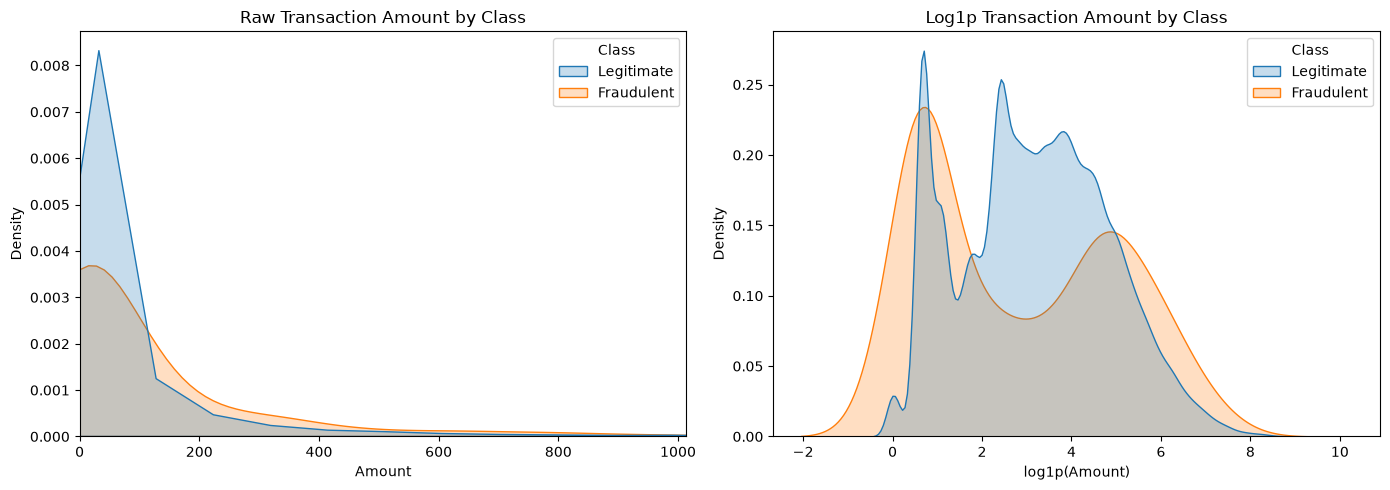

2026-11-01 09:47:07,852 | INFO | Amount transformation figure saved to: c:\Users\use\Desktop\Credit Card Fraud Detection\reports\figures\amount_log1p_transformation.png


In [7]:
def plot_amount_transformations(
    features: pd.DataFrame,
    target: pd.Series,
    output_path: Path,
) -> None:
    """Compare raw Amount and log1p(Amount) distributions by class."""
    plot_data = features[["Amount", "Amount_log1p"]].copy()
    plot_data["Class"] = target.map({0: "Legitimate", 1: "Fraudulent"}).values

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.kdeplot(
        data=plot_data,
        x="Amount",
        hue="Class",
        common_norm=False,
        fill=True,
        ax=axes[0],
    )
    axes[0].set_title("Raw Transaction Amount by Class")
    axes[0].set_xlabel("Amount")
    axes[0].set_ylabel("Density")
    axes[0].set_xlim(0, np.quantile(features["Amount"], 0.99))

    sns.kdeplot(
        data=plot_data,
        x="Amount_log1p",
        hue="Class",
        common_norm=False,
        fill=True,
        ax=axes[1],
    )
    axes[1].set_title("Log1p Transaction Amount by Class")
    axes[1].set_xlabel("log1p(Amount)")
    axes[1].set_ylabel("Density")

    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


amount_transformation_figure_path = (
    FIGURES_DIR / "amount_log1p_transformation.png"
)

plot_amount_transformations(
    features=full_engineered_train_features,
    target=y_train,
    output_path=amount_transformation_figure_path,
)

logger.info(
    "Amount transformation figure saved to: %s",
    amount_transformation_figure_path,
)

In [15]:
from sklearn.metrics import average_precision_score


def create_logistic_regression_pipeline() -> Pipeline:
    """Create a Logistic Regression pipeline with training-only scaling."""
    return Pipeline(
        steps=[
            ("standard_scaler", StandardScaler()),
            (
                "logistic_regression",
                LogisticRegression(
                    max_iter=1000,
                    random_state=RANDOM_SEED,
                    solver="lbfgs",
                ),
            ),
        ]
    )


def evaluate_classification_predictions(
    y_true: pd.Series,
    y_pred: np.ndarray,
    y_score: np.ndarray,
    threshold: float,
) -> dict:
    """Calculate evaluation metrics suitable for imbalanced fraud detection."""
    confusion = confusion_matrix(y_true, y_pred, labels=[0, 1])
    true_negative, false_positive, false_negative, true_positive = confusion.ravel()

    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    false_positive_rate = (
        false_positive / (false_positive + true_negative)
        if (false_positive + true_negative) > 0
        else 0.0
    )

    has_both_classes = len(np.unique(y_true)) > 1

    return {
        "threshold": threshold,
        "precision": float(precision),
        "recall": float(recall),
        "f1_score": float(f1),
        "pr_auc": (
            float(average_precision_score(y_true, y_score))
            if has_both_classes
            else np.nan
        ),
        "roc_auc": (
            float(roc_auc_score(y_true, y_score))
            if has_both_classes
            else np.nan
        ),
        "false_positive_rate": float(false_positive_rate),
        "true_positives": int(true_positive),
        "false_positives": int(false_positive),
        "true_negatives": int(true_negative),
        "false_negatives": int(false_negative),
        "transactions_flagged": int(true_positive + false_positive),
    }


def train_and_evaluate_baseline(
    configuration_name: str,
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_validation: pd.DataFrame,
    y_validation: pd.Series,
) -> tuple[dict, Pipeline, np.ndarray]:
    """Train and evaluate one Logistic Regression feature configuration."""
    X_train_configured, train_columns = build_feature_configuration(
        features=X_train,
        configuration_name=configuration_name,
    )

    X_validation_configured, validation_columns = build_feature_configuration(
        features=X_validation,
        configuration_name=configuration_name,
    )

    if train_columns != validation_columns:
        raise ValueError("Training and validation feature columns do not match.")

    pipeline = create_logistic_regression_pipeline()

    training_start_time = time.time()
    pipeline.fit(X_train_configured, y_train)
    training_duration = time.time() - training_start_time

    validation_scores = pipeline.predict_proba(X_validation_configured)[:, 1]
    validation_predictions = (validation_scores >= DEFAULT_THRESHOLD).astype(int)

    metrics = evaluate_classification_predictions(
        y_true=y_validation,
        y_pred=validation_predictions,
        y_score=validation_scores,
        threshold=DEFAULT_THRESHOLD,
    )

    metrics.update(
        {
            "model": "Logistic Regression",
            "feature_configuration": configuration_name,
            "imbalance_strategy": "None",
            "preprocessing": "StandardScaler fitted on training data only",
            "training_duration_seconds": training_duration,
            "feature_count": len(train_columns),
        }
    )

    return metrics, pipeline, validation_scores

In [16]:
baseline_results = []
trained_pipelines = {}
validation_scores_by_configuration = {}

for configuration_name in FEATURE_CONFIGURATIONS:
    logger.info("Training configuration: %s", configuration_name)

    result, pipeline, validation_scores = train_and_evaluate_baseline(
        configuration_name=configuration_name,
        X_train=X_train,
        y_train=y_train,
        X_validation=X_validation,
        y_validation=y_validation,
    )

    baseline_results.append(result)
    trained_pipelines[configuration_name] = pipeline
    validation_scores_by_configuration[configuration_name] = validation_scores

baseline_results_dataframe = pd.DataFrame(baseline_results)

baseline_results_dataframe[
    [
        "feature_configuration",
        "precision",
        "recall",
        "f1_score",
        "pr_auc",
        "roc_auc",
        "false_positive_rate",
        "transactions_flagged",
        "false_positives",
        "false_negatives",
        "training_duration_seconds",
    ]
]

2026-11-01 09:57:16,370 | INFO | Training configuration: original_features
2026-11-01 09:57:17,302 | INFO | Training configuration: original_plus_log_amount
2026-11-01 09:57:18,672 | INFO | Training configuration: log_amount_and_time_hours


,feature_configuration,precision,recall,f1_score,pr_auc,roc_auc,false_positive_rate,transactions_flagged,false_positives,false_negatives,training_duration_seconds
0,original_features,0.833333,0.492958,0.619469,0.687661,0.964885,0.000165,42,7,36,0.789457
1,original_plus_log_amount,0.837209,0.507042,0.631579,0.691636,0.960886,0.000165,43,7,35,1.121398
2,log_amount_and_time_hours,0.837209,0.507042,0.631579,0.693844,0.961380,0.000165,43,7,35,0.972790


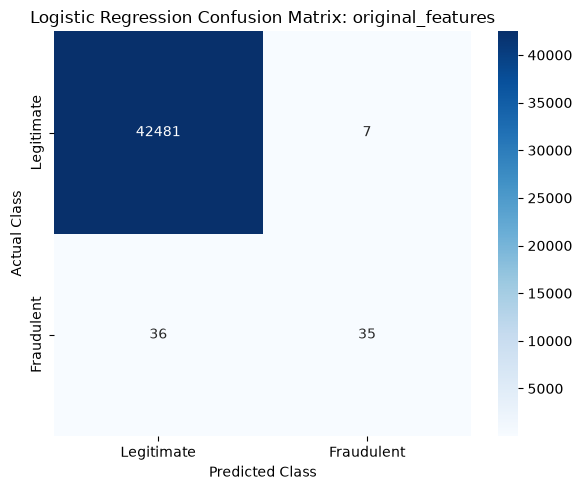

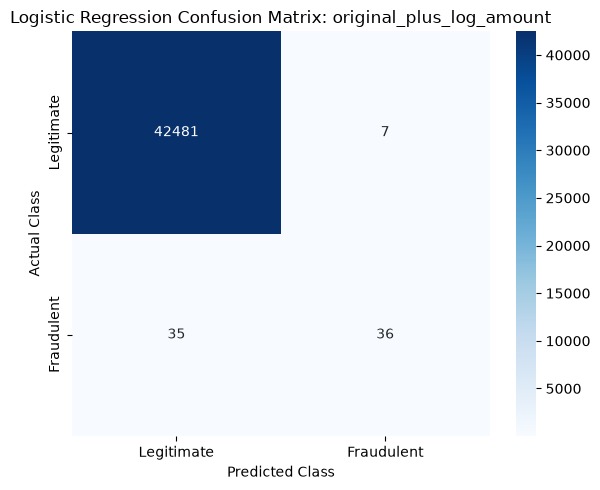

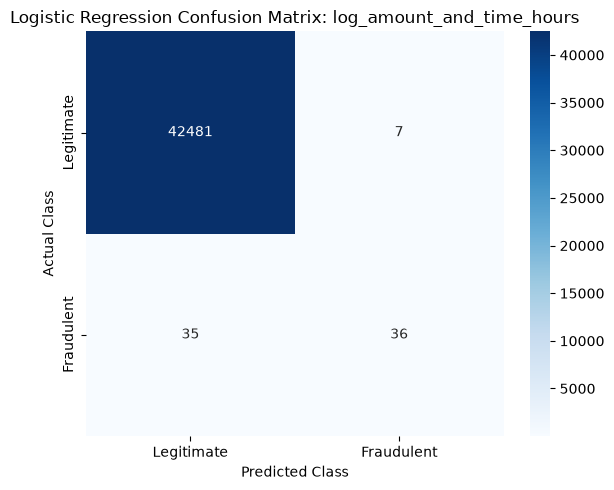

2026-11-01 09:57:21,707 | INFO | Baseline confusion matrices generated.


In [17]:
def plot_confusion_matrix(
    y_true: pd.Series,
    y_score: np.ndarray,
    threshold: float,
    title: str,
    output_path: Path,
) -> None:
    """Plot a confusion matrix for a configured decision threshold."""
    predictions = (y_score >= threshold).astype(int)
    confusion = confusion_matrix(y_true, predictions, labels=[0, 1])

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        confusion,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Legitimate", "Fraudulent"],
        yticklabels=["Legitimate", "Fraudulent"],
    )
    plt.title(title)
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


for configuration_name in FEATURE_CONFIGURATIONS:
    plot_confusion_matrix(
        y_true=y_validation,
        y_score=validation_scores_by_configuration[configuration_name],
        threshold=DEFAULT_THRESHOLD,
        title=f"Logistic Regression Confusion Matrix: {configuration_name}",
        output_path=FIGURES_DIR / f"baseline_confusion_matrix_{configuration_name}.png",
    )

logger.info("Baseline confusion matrices generated.")

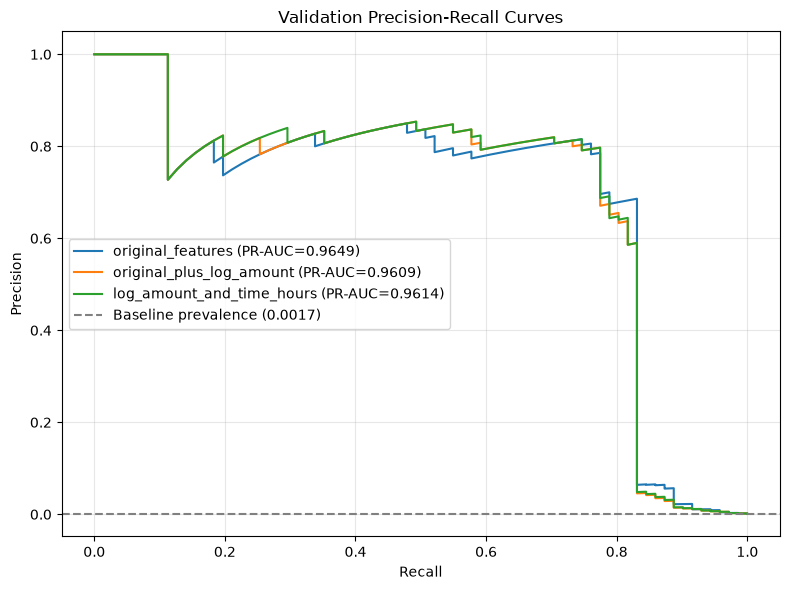

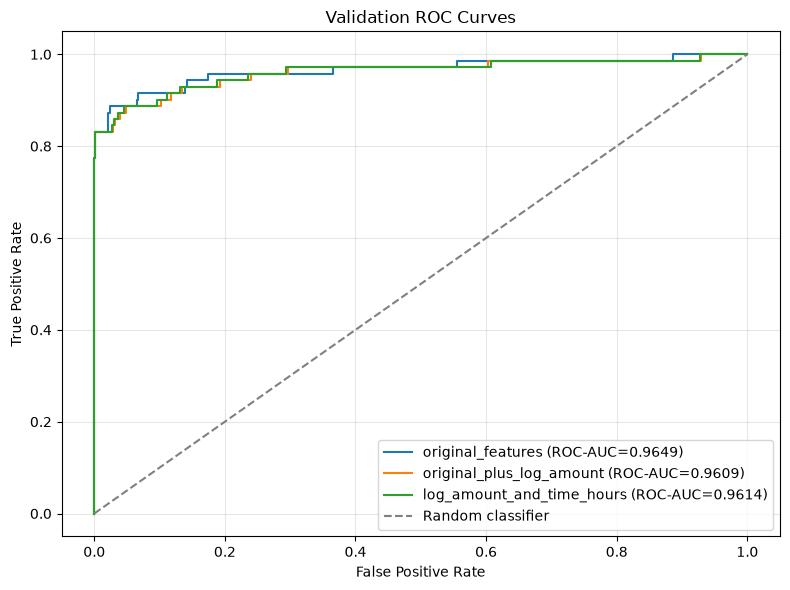

2026-11-01 09:57:23,827 | INFO | Baseline precision-recall and ROC curves generated.


In [18]:
def plot_precision_recall_curves(
    y_true: pd.Series,
    scores_by_configuration: dict[str, np.ndarray],
    output_path: Path,
) -> None:
    """Plot validation precision-recall curves for all configurations."""
    plt.figure(figsize=(8, 6))

    for configuration_name, scores in scores_by_configuration.items():
        precision_values, recall_values, _ = precision_recall_curve(
            y_true,
            scores,
        )
        pr_auc = roc_auc_score(y_true, scores)

        plt.plot(
            recall_values,
            precision_values,
            label=f"{configuration_name} (PR-AUC={pr_auc:.4f})",
        )

    fraud_prevalence = y_true.mean()
    plt.axhline(
        fraud_prevalence,
        color="gray",
        linestyle="--",
        label=f"Baseline prevalence ({fraud_prevalence:.4f})",
    )

    plt.title("Validation Precision-Recall Curves")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


def plot_roc_curves(
    y_true: pd.Series,
    scores_by_configuration: dict[str, np.ndarray],
    output_path: Path,
) -> None:
    """Plot validation ROC curves for all configurations."""
    plt.figure(figsize=(8, 6))

    for configuration_name, scores in scores_by_configuration.items():
        false_positive_rate, true_positive_rate, _ = roc_curve(
            y_true,
            scores,
        )
        roc_auc = roc_auc_score(y_true, scores)

        plt.plot(
            false_positive_rate,
            true_positive_rate,
            label=f"{configuration_name} (ROC-AUC={roc_auc:.4f})",
        )

    plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random classifier")

    plt.title("Validation ROC Curves")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


precision_recall_figure_path = (
    FIGURES_DIR / "baseline_precision_recall_curves.png"
)
roc_figure_path = FIGURES_DIR / "baseline_roc_curves.png"

plot_precision_recall_curves(
    y_true=y_validation,
    scores_by_configuration=validation_scores_by_configuration,
    output_path=precision_recall_figure_path,
)

plot_roc_curves(
    y_true=y_validation,
    scores_by_configuration=validation_scores_by_configuration,
    output_path=roc_figure_path,
)

logger.info("Baseline precision-recall and ROC curves generated.")

In [19]:
def save_baseline_artifacts(
    pipeline: Pipeline,
    feature_columns: list[str],
    metrics: dict,
    output_directory: Path,
) -> dict:
    """Save the selected baseline pipeline and its metadata."""
    output_directory.mkdir(parents=True, exist_ok=True)

    model_path = output_directory / "baseline_logistic_regression.joblib"
    metadata_path = output_directory / "baseline_metadata.json"

    joblib.dump(pipeline, model_path)

    metadata = {
        "model_name": "Logistic Regression",
        "model_type": "baseline_supervised_classifier",
        "feature_configuration": metrics["feature_configuration"],
        "feature_columns": feature_columns,
        "target_column": "Class",
        "decision_threshold": DEFAULT_THRESHOLD,
        "random_seed": RANDOM_SEED,
        "preprocessing": metrics["preprocessing"],
        "validation_metrics": metrics,
        "artifact_note": (
            "This is a Phase 4 baseline artifact, not the final production model."
        ),
    }

    with metadata_path.open("w", encoding="utf-8") as file:
        json.dump(metadata, file, indent=2, default=str)

    return {
        "model_path": str(model_path),
        "metadata_path": str(metadata_path),
    }


best_configuration = baseline_results_dataframe.loc[
    baseline_results_dataframe["pr_auc"].idxmax(),
    "feature_configuration",
]

best_pipeline = trained_pipelines[best_configuration]
best_metrics = baseline_results_dataframe[
    baseline_results_dataframe["feature_configuration"] == best_configuration
].iloc[0].to_dict()

if best_configuration == "original_features":
    best_feature_columns = original_train_columns
elif best_configuration == "original_plus_log_amount":
    best_feature_columns = log_amount_train_columns
else:
    best_feature_columns = full_engineered_train_columns

baseline_artifact_paths = save_baseline_artifacts(
    pipeline=best_pipeline,
    feature_columns=best_feature_columns,
    metrics=best_metrics,
    output_directory=MODELS_DIR,
)

logger.info(
    "Best validation PR-AUC configuration: %s",
    best_configuration,
)
logger.info(
    "Baseline artifacts saved: %s",
    baseline_artifact_paths,
)

2026-11-01 09:57:23,853 | INFO | Best validation PR-AUC configuration: log_amount_and_time_hours
2026-11-01 09:57:23,854 | INFO | Baseline artifacts saved: {'model_path': 'c:\\Users\\use\\Desktop\\Credit Card Fraud Detection\\models\\supervised\\baseline_logistic_regression\\baseline_logistic_regression.joblib', 'metadata_path': 'c:\\Users\\use\\Desktop\\Credit Card Fraud Detection\\models\\supervised\\baseline_logistic_regression\\baseline_metadata.json'}


In [20]:
def save_phase4_results(
    results_dataframe: pd.DataFrame,
    output_directory: Path,
) -> tuple[Path, Path]:
    """Save the feature-engineering comparison and evaluation report."""
    output_directory.mkdir(parents=True, exist_ok=True)

    comparison_path = output_directory / "model_comparison.csv"
    report_path = output_directory / "feature_engineering_report.md"

    results_dataframe.to_csv(comparison_path, index=False)

    report_lines = [
        "# Feature Engineering and Baseline Results",
        "",
        "## Scope",
        "",
        "- Model: Logistic Regression",
        "- Evaluation dataset: Validation set",
        "- Decision threshold: 0.5",
        "- Test set: Not used in this phase",
        "",
        "## Feature Configurations",
        "",
    ]

    for _, row in results_dataframe.iterrows():
        report_lines.extend(
            [
                f"### {row['feature_configuration']}",
                "",
                f"- Precision: {row['precision']:.4f}",
                f"- Recall: {row['recall']:.4f}",
                f"- F1-score: {row['f1_score']:.4f}",
                f"- PR-AUC: {row['pr_auc']:.4f}",
                f"- ROC-AUC: {row['roc_auc']:.4f}",
                f"- False-positive rate: {row['false_positive_rate']:.6f}",
                f"- Transactions flagged: {row['transactions_flagged']:,}",
                f"- False positives: {row['false_positives']:,}",
                f"- False negatives: {row['false_negatives']:,}",
                f"- Training duration: {row['training_duration_seconds']:.2f} seconds",
                "",
            ]
        )

    report_lines.extend(
        [
            "## Interpretation",
            "",
            "- These are validation results, not final generalization estimates.",
            "- PR-AUC is the primary ranking metric because fraud is extremely rare.",
            "- A higher recall can increase false positives; both must be considered together.",
            "- The selected baseline is chosen using validation PR-AUC only.",
            "- The untouched test set remains reserved for final evaluation.",
        ]
    )

    report_path.write_text("\n".join(report_lines), encoding="utf-8")

    return comparison_path, report_path


model_comparison_path, feature_engineering_report_path = save_phase4_results(
    results_dataframe=baseline_results_dataframe,
    output_directory=REPORTS_DIR,
)

logger.info("Model comparison saved to: %s", model_comparison_path)
logger.info(
    "Feature engineering report saved to: %s",
    feature_engineering_report_path,
)

2026-11-01 09:57:23,880 | INFO | Model comparison saved to: c:\Users\use\Desktop\Credit Card Fraud Detection\reports\model_comparison.csv
2026-11-01 09:57:23,882 | INFO | Feature engineering report saved to: c:\Users\use\Desktop\Credit Card Fraud Detection\reports\feature_engineering_report.md


In [ ]:
required_phase4_artifacts = [
    amount_transformation_figure_path,
    precision_recall_figure_path,
    roc_figure_path,
    model_comparison_path,
    feature_engineering_report_path,
    Path(baseline_artifact_paths["model_path"]),
    Path(baseline_artifact_paths["metadata_path"]),
]

missing_artifacts = [
    path for path in required_phase4_artifacts if not path.exists()
]

if missing_artifacts:
    raise FileNotFoundError(
        f"Missing Phase 4 artifacts: {[str(path) for path in missing_artifacts]}"
    )

logger.info("All required Phase 4 artifacts were generated successfully.")
print("Phase 4 feature engineering and baseline modelling completed successfully.")

2026-11-01 09:57:23,897 | INFO | All required Phase 4 artifacts were generated successfully.


Phase 4 feature engineering and baseline modelling completed successfully.
